# CXC103

Includes Data Augmentation on training 

In [15]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import keras
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)

from src.utils import (
    generate_confusion, 
    generate_roc_curve, 
    plot_train_accuracy, 
    plot_train_loss, 
    get_dataset_distribution
)


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
load_dotenv()


dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC1.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data04", "train")
test_data_dir = os.path.join(dataset_path, "data04", "test")
val_data_dir = os.path.join(dataset_path, "data04", "val")


# Set parameters
IMG_SIZE = (384, 384)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data04/train
/Users/joshan/Documents/final-year-project/dataset/data04/test
/Users/joshan/Documents/final-year-project/dataset/data04/val


In [16]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     6083 │        6165 │           5924 │      1155 │   19327 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 6083,
  'PNEUMONIA': 6165,
  'TUBERCULOSIS': 5924,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [17]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode='rgb',
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 19326 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


In [18]:
class_names = train_ds.class_names

print("Class names:", class_names)

for i, label in enumerate(class_names):
    print(f"Index {i}: {label}")

Class names: ['NORMAL', 'PNEUMONIA', 'TUBERCULOSIS', 'UNKNOWN']
Index 0: NORMAL
Index 1: PNEUMONIA
Index 2: TUBERCULOSIS
Index 3: UNKNOWN


In [19]:
data_augmentation = models.Sequential([
    
    # Flip left-right (lungs are symmetric)
    layers.RandomFlip("horizontal"),
    
    # Small rotation for positioning differences
    layers.RandomRotation(0.05),
    
    # Slight zoom to simulate distance from scanner
    layers.RandomZoom(0.1),
    
    # Small translation for patient positioning
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    
    # Slight contrast variation from different scanners
    layers.RandomContrast(0.1),
    
])

In [ ]:
model = models.Sequential([

    data_augmentation,
    # Preprocessing: Rescale inputs to [0, 1]
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # First convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Second convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Third convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),


    # Third convolutional Block
    layers.Conv2D(256, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),  
    layers.Dropout(0.5), # Helps prevent overfitting by dropping out 0.5 acc 
    layers.Dense(4, activation='softmax') # Softmax for multi-class probability
])

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Epoch 1/10


2026-05-08 01:09:16.274727: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


604/604 ━━━━━━━━━━━━━━━━━━━━ 591s 953ms/step - accuracy: 0.8005 - loss: 0.5973 - val_accuracy: 0.7595 - val_loss: 0.6261
Epoch 2/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 552s 913ms/step - accuracy: 0.8490 - loss: 0.4278 - val_accuracy: 0.8909 - val_loss: 0.3984
Epoch 3/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 554s 917ms/step - accuracy: 0.8645 - loss: 0.3741 - val_accuracy: 0.9133 - val_loss: 0.2549
Epoch 4/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 540s 894ms/step - accuracy: 0.8757 - loss: 0.3395 - val_accuracy: 0.7083 - val_loss: 0.9920
Epoch 5/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 548s 907ms/step - accuracy: 0.8831 - loss: 0.3215 - val_accuracy: 0.6439 - val_loss: 1.4979
Epoch 6/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 547s 905ms/step - accuracy: 0.8900 - loss: 0.3002 - val_accuracy: 0.9225 - val_loss: 0.2140
Epoch 7/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 549s 909ms/step - accuracy: 0.8922 - loss: 0.2989 - val_accuracy: 0.9238 - val_loss: 0.2388
Epoch 8/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 550s 910ms/step - accuracy: 0.9024 - loss: 0.27

In [10]:
# Save the model
model.save('CXC1033.keras')
print("Model saved successfully!")

Model saved successfully!


In [22]:
model = tf.keras.models.load_model('CXC1033.keras')

In [23]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 8s 137ms/step - accuracy: 0.7937 - loss: 0.6144
Test Loss: 0.6144043207168579
Test Accuracy: 79.37%


In [24]:
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 144ms/step - accuracy: 0.8160 - loss: 0.5459
Test Loss: 0.5459286570549011
Test Accuracy: 81.60%


2026-05-08 19:40:00.304896: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


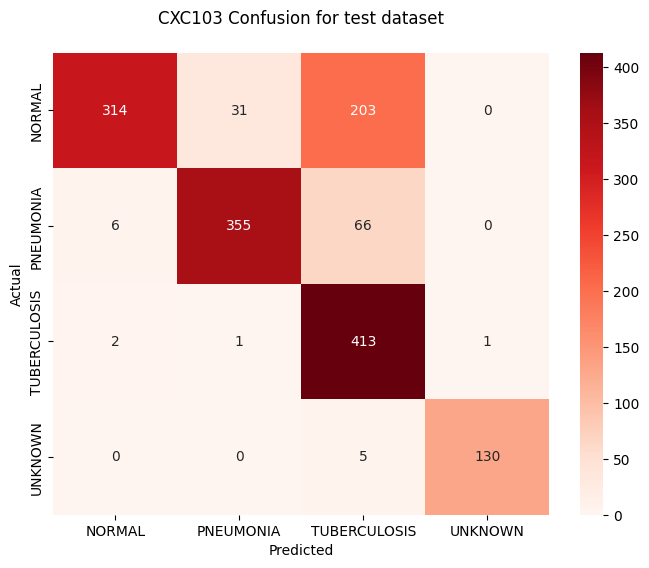

              precision    recall  f1-score   support

      NORMAL       0.98      0.57      0.72       548
   PNEUMONIA       0.92      0.83      0.87       427
TUBERCULOSIS       0.60      0.99      0.75       417
     UNKNOWN       0.99      0.96      0.98       135

    accuracy                           0.79      1527
   macro avg       0.87      0.84      0.83      1527
weighted avg       0.86      0.79      0.79      1527



In [25]:
generate_confusion(test_ds, model=model, title="CXC103 Confusion for test dataset")

2026-05-07 08:10:17.617176: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


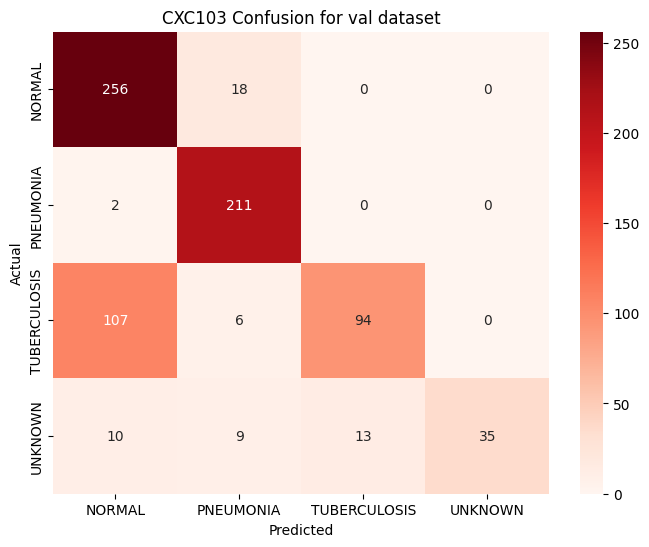

              precision    recall  f1-score   support

      NORMAL       0.68      0.93      0.79       274
   PNEUMONIA       0.86      0.99      0.92       213
TUBERCULOSIS       0.88      0.45      0.60       207
     UNKNOWN       1.00      0.52      0.69        67

    accuracy                           0.78       761
   macro avg       0.86      0.73      0.75       761
weighted avg       0.81      0.78      0.77       761



In [15]:
generate_confusion(val_ds, model=model, title="CXC103 Confusion for val dataset")

2026-05-08 12:23:36.110631: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


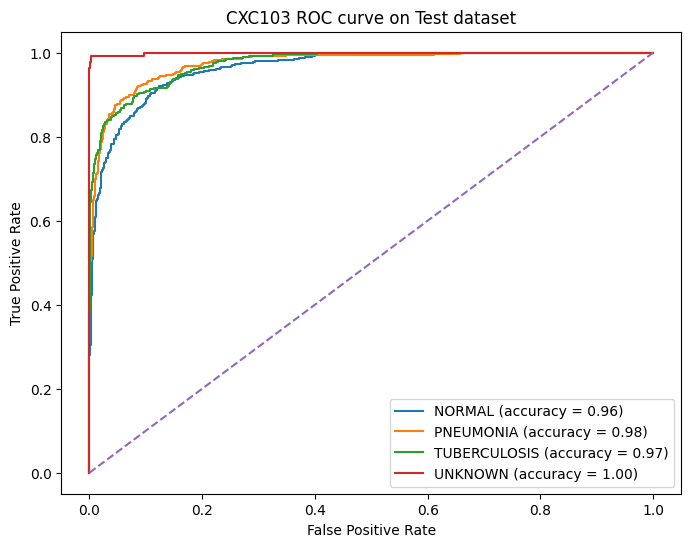

In [19]:
generate_roc_curve(test_ds, model=model, title="CXC103 ROC curve on Test dataset")

2026-05-07 08:11:20.665960: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


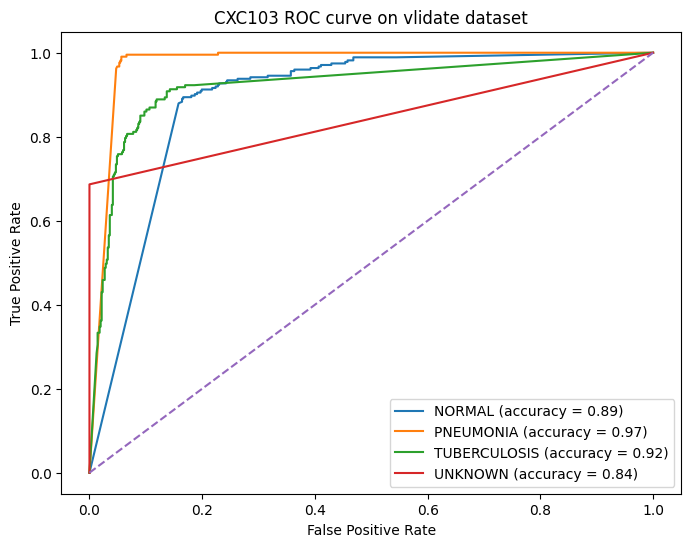

In [17]:
generate_roc_curve(val_ds, model=model, title="CXC103 ROC curve on vlidate dataset")